# Experiment 28: Deep Boltzmann Machine / Convolutional Boltzmann Machine Simulation

A textile company models local fabric texture patterns. We implement a compact two-hidden-layer DBM-style mean-field approximation, generate reconstructions/samples and compare reconstruction quality with a single-hidden-layer RBM baseline.

**Tools:** NumPy, SciPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Build a two-hidden-layer model with mean-field inference.  2. Train with an approximate positive/negative phase.  3. Visualise filters and hidden activations.  4. Generate samples and reconstructions.  5. Compare against a single-layer RBM baseline.

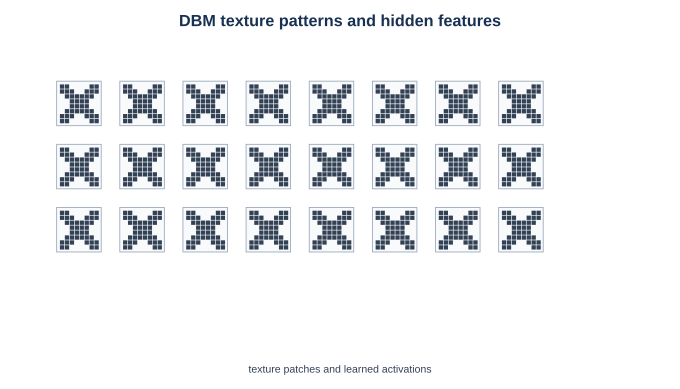

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

rng=np.random.default_rng(28)
# 16x16 grayscale texture patches with horizontal, vertical or checker patterns.
def make_texture(n=240):
    out=[]
    yy,xx=np.mgrid[0:16,0:16]
    for i in range(n):
        base=[(yy%4<2),(xx%4<2),((xx//2+yy//2)%2==0)][i%3].astype(float)
        out.append((rng.random(256)<np.clip(base.ravel()+rng.normal(0,.15,256),0,1)).astype(float))
    return np.array(out)
V=make_texture()
# Single-layer RBM baseline.
W0=rng.normal(0,.02,(256,48));a0=np.zeros(256);b0=np.zeros(48)
for _ in range(8):
    for s in range(0,len(V),32):
        v=V[s:s+32];ph=expit(v@W0+b0);h=(rng.random(ph.shape)<ph)
        pv=expit(h@W0.T+a0);vn=(rng.random(pv.shape)<pv);phn=expit(vn@W0+b0)
        W0+=.02*(v.T@ph-vn.T@phn)/len(v);a0+=.02*(v-vn).mean(0);b0+=.02*(ph-phn).mean(0)
single_recon=expit(expit(V@W0+b0)@W0.T+a0)

# Two hidden layers, trained with a short mean-field/contrastive-divergence approximation.
W1=rng.normal(0,.02,(256,64));W2=rng.normal(0,.02,(64,32))
a=np.zeros(256);b1=np.zeros(64);b2=np.zeros(32)
def mean_field(v,iterations=4):
    h1=np.full((len(v),64),.5);h2=np.full((len(v),32),.5)
    for _ in range(iterations):
        h1=expit(v@W1+b1+h2@W2.T)
        h2=expit(h1@W2+b2)
    return h1,h2
for _ in range(10):
    for s in range(0,len(V),32):
        v0=V[s:s+32];pos1,pos2=mean_field(v0)
        vneg=expit(pos1@W1.T+a)
        neg1,neg2=mean_field(vneg)
        W1+=.02*(v0.T@pos1-vneg.T@neg1)/len(v0)
        W2+=.02*(pos1.T@pos2-neg1.T@neg2)/len(v0)
        a+=.02*(v0-vneg).mean(0);b1+=.02*(pos1-neg1).mean(0);b2+=.02*(pos2-neg2).mean(0)
h1,h2=mean_field(V)
dbm_recon=expit(h1@W1.T+a)
print("Single-layer RBM reconstruction MSE:",round(np.mean((V-single_recon)**2),4))
print("Two-layer DBM approximation MSE:",round(np.mean((V-dbm_recon)**2),4))

fig,axes=plt.subplots(2,6,figsize=(10,4))
for i in range(6):
    axes[0,i].imshow(W1[:,i].reshape(16,16),cmap="gray");axes[0,i].axis("off")
    axes[1,i].imshow(h1[i].reshape(8,8),cmap="magma");axes[1,i].axis("off")
axes[0,0].set_ylabel("filters");axes[1,0].set_ylabel("hidden units")
plt.suptitle("DBM first-layer filters and activations");plt.tight_layout();plt.show()
fig,axes=plt.subplots(3,6,figsize=(9,5))
for i in range(6):
    axes[0,i].imshow(V[i].reshape(16,16),cmap="gray")
    axes[1,i].imshow(single_recon[i].reshape(16,16),cmap="gray")
    axes[2,i].imshow(dbm_recon[i].reshape(16,16),cmap="gray")
    for r in range(3):axes[r,i].axis("off")
axes[0,0].set_ylabel("original");axes[1,0].set_ylabel("RBM");axes[2,0].set_ylabel("DBM")
plt.tight_layout();plt.show()
# A short Gibbs-like sample starts from random binary pixels and alternates latent means.
sample=(rng.random((1,256))<.5).astype(float)
for _ in range(30):
    q1,q2=mean_field(sample)
    sample=(rng.random((1,256))<expit(q1@W1.T+a)).astype(float)
plt.figure(figsize=(2,2));plt.imshow(sample.reshape(16,16),cmap="gray");plt.title("DBM-style sample");plt.axis("off");plt.show()